# Assignment 1 — Data Profiling (EDA) Report

**Dataset:** UCI Online Retail  
**Team:** ZHANG KAIYI (A207404); YANG LIZIXUAN (A207402); YUAN YIWEI (A207421); ZHOU XIUSHI (A207418)

This notebook profiles transaction data and documents quality decisions. It does not train a model.


## 1. Scenario

A UK-based online retailer records product lines for transactions, including cancellations and customers from several countries. This open dataset is suitable for profiling because transaction records can have missing identifiers or descriptions, extreme quantities and prices, and inconsistent business meaning. The main questions are which rows represent usable completed sales, which unusual values are legitimate, and what privacy or country-coverage limits remain.


## 2. Data source and field meanings

**Source:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), dataset ID 352, DOI [10.24432/C5BW33](https://doi.org/10.24432/C5BW33). UCI describes transactions from 1 December 2010 to 9 December 2011 for a UK-based online retailer. The original `Online Retail.xlsx` is stored in `data/`; if it is absent, the next cell downloads UCI's official ZIP and extracts the workbook. No synthetic rows or deliberately introduced defects are used. Dataset credit: Chen, D. (2015), *Online Retail*, UCI Machine Learning Repository, CC BY 4.0.

| Field | Meaning |
|---|---|
| InvoiceNo | Transaction invoice number; a leading `C` indicates a cancellation |
| StockCode | Product code |
| Description | Product description |
| Quantity | Item quantity on the transaction line |
| InvoiceDate | Transaction date and time |
| UnitPrice | Price per item in pounds sterling |
| CustomerID | Customer identifier; potentially linkable to a person |
| Country | Customer's country |

**Unit of observation:** one workbook row is a product line, not necessarily one unique invoice or customer. Counts and country shares below are therefore *row shares*. Source metadata may differ from missing values observed in the workbook; the workbook itself is profiled below.


In [1]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
sns.set_theme(style="whitegrid")
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
DATA_FILE = DATA_DIR / "Online Retail.xlsx"
UCI_PAGE = "https://archive.ics.uci.edu/dataset/352/online+retail"
UCI_ZIP = "https://archive.ics.uci.edu/static/public/352/online%2Bretail.zip"

if not DATA_FILE.exists():
    try:
        with urlopen(UCI_ZIP, timeout=120) as response:
            archive_bytes = response.read()
        with ZipFile(BytesIO(archive_bytes)) as archive:
            names = [name for name in archive.namelist() if name.lower().endswith("online retail.xlsx")]
            if len(names) != 1:
                raise ValueError(f"Expected one Online Retail workbook; found {names}")
            DATA_FILE.write_bytes(archive.read(names[0]))
        print(f"Downloaded the original workbook from {UCI_ZIP}")
    except Exception as exc:
        raise RuntimeError(
            f"Could not download the official UCI workbook: {exc}. "
            f"Open {UCI_PAGE}, click Download, extract 'Online Retail.xlsx' "
            f"and place it at {DATA_FILE.resolve()}, then rerun this cell."
        ) from exc
print(f"Using original UCI workbook: {DATA_FILE} ({DATA_FILE.stat().st_size:,} bytes)")
raw_df = pd.read_excel(DATA_FILE, engine="openpyxl")
assert len(raw_df) > 0 and len(raw_df.columns) == 8, "Unexpected workbook shape."
print(f"Original records: {len(raw_df):,}")


Using original UCI workbook: data/Online Retail.xlsx (23,715,344 bytes)


Original records: 541,909


## 3. Initial profiling of untouched data

The following checks use `raw_df` exactly as read from the workbook. In particular, missing values and exact duplicates are counted before any cleaning decision. Pandas may infer `CustomerID` as a floating type because of blanks; that does not make it a numerical measurement.


In [2]:
print("Shape (rows, columns):", raw_df.shape)
sample_rows = raw_df.head(5).copy()
sample_rows["CustomerID"] = sample_rows["CustomerID"].map(
    lambda value: "<present>" if pd.notna(value) else "<missing>"
)
display(sample_rows)
print("Column names:", list(raw_df.columns))
display(raw_df.dtypes.rename("inferred dtype").to_frame())
display(raw_df.describe(include="all").T)
raw_missing = raw_df.isna().sum()
raw_missing_pct = raw_missing.div(len(raw_df)).mul(100)
display(pd.DataFrame({"Missing rows": raw_missing, "Missing %": raw_missing_pct.round(2)}))
raw_duplicate_count = int(raw_df.duplicated().sum())
print(f"Exact duplicate rows beyond first occurrence: {raw_duplicate_count:,} "
      f"({raw_duplicate_count / len(raw_df):.2%})")


Shape (rows, columns): (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,<present>,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,<present>,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,<present>,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,<present>,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,<present>,United Kingdom


Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,inferred dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing rows,Missing %
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Exact duplicate rows beyond first occurrence: 5,268 (0.97%)


## 4. Missing-value analysis and policy

The workbook is a line-level transaction file. A missing `CustomerID` prevents customer-level work but does not necessarily invalidate a product sale; it is flagged and never filled with a fabricated ID. A missing or blank `Description` prevents reliable product interpretation, so such lines remain visible in the audit copy and are excluded from the sales-ready view. No global imputation is justified.

Blank cells are not the only form of missingness. `Country` contains the placeholder label **`Unspecified`**, which is a missing value disguised as a category. It is recoded to a true missing value and flagged. Those lines are kept in the sales view because the sale itself is valid, but they cannot support country-level comparisons.

The same cell also fixes data types: identifiers are stored as strings rather than numbers, dates are parsed, and numeric measures are coerced.

In [3]:
audit_df = raw_df.copy(deep=True)
for col in ["InvoiceNo", "StockCode", "Description", "Country"]:
    audit_df[col] = audit_df[col].astype("string").str.strip()
audit_df["InvoiceDate"] = pd.to_datetime(audit_df["InvoiceDate"], errors="coerce")
audit_df["Quantity"] = pd.to_numeric(audit_df["Quantity"], errors="coerce")
audit_df["UnitPrice"] = pd.to_numeric(audit_df["UnitPrice"], errors="coerce")
# CustomerID is an identifier, not a measurement: 17850.0 -> "17850", blanks stay <NA>
audit_df["CustomerID"] = audit_df["CustomerID"].astype("Int64").astype("string")

def is_blank(col):
    return audit_df[col].isna() | audit_df[col].eq("").fillna(False)

# True blanks are measured before any placeholder recoding
audit_df["Description_missing"] = is_blank("Description")
audit_df["InvoiceNo_missing"] = is_blank("InvoiceNo")
audit_df["StockCode_missing"] = is_blank("StockCode")
audit_df["Country_missing"] = is_blank("Country")
audit_df["InvoiceDate_invalid"] = audit_df["InvoiceDate"].isna()
audit_df["CustomerID_present"] = audit_df["CustomerID"].notna()

# Disguised missingness: a placeholder label instead of a blank cell
audit_df["Country_unspecified"] = audit_df["Country"].eq("Unspecified").fillna(False)
audit_df.loc[audit_df["Country_unspecified"], "Country"] = pd.NA

missing_table = pd.DataFrame({"Blank cells": raw_missing, "Blank %": raw_missing_pct.round(2)})
missing_table["Placeholder values"] = 0
missing_table.loc["Country", "Placeholder values"] = int(audit_df["Country_unspecified"].sum())
missing_table["Effective missing %"] = (
    (missing_table["Blank cells"] + missing_table["Placeholder values"]).div(len(raw_df)).mul(100).round(2)
)
display(missing_table)

no_desc = audit_df[audit_df["Description_missing"]]
display(Markdown(
    f"The raw workbook has **{raw_missing['CustomerID']:,}** missing customer IDs "
    f"({raw_missing_pct['CustomerID']:.2f}%), **{raw_missing['Description']:,}** missing product "
    f"descriptions ({raw_missing_pct['Description']:.2f}%) and "
    f"**{int(audit_df['Country_unspecified'].sum()):,}** `Unspecified` country labels. "
    f"Of the {len(no_desc):,} lines without a description, **{int(no_desc['UnitPrice'].eq(0).sum()):,}** have a zero "
    f"unit price and **{int((~no_desc['CustomerID_present']).sum()):,}** have no customer ID. "
    "They look like stock or system adjustments rather than sales, which supports excluding them "
    "from the sales view instead of inventing descriptions. Customer IDs are not imputed."
))

,Blank cells,Blank %,Placeholder values,Effective missing %
InvoiceNo,0,0.00,0,0.00
StockCode,0,0.00,0,0.00
Description,1454,0.27,0,0.27
Quantity,0,0.00,0,0.00
InvoiceDate,0,0.00,0,0.00
UnitPrice,0,0.00,0,0.00
CustomerID,135080,24.93,0,24.93
Country,0,0.00,446,0.08


The raw workbook has **135,080** missing customer IDs (24.93%), **1,454** missing product descriptions (0.27%) and **446** `Unspecified` country labels. Of the 1,454 lines without a description, **1,454** have a zero unit price and **1,454** have no customer ID. They look like stock or system adjustments rather than sales, which supports excluding them from the sales view instead of inventing descriptions. Customer IDs are not imputed.

## 5. Outlier detection and handling

**Detection.** IQR fences (1.5 × IQR) are calculated on the original `Quantity` and `UnitPrice` columns, including cancellations and zero-price records, so they describe the unmodified distribution. IQR is a diagnostic rule, not a business-validity rule: on heavy-tailed wholesale data it flags a large share of rows, so the flagged rows are **not dropped or capped automatically**. Instead, the most extreme rows are inspected (5.1) and outliers are classified by what they *are* rather than by how large they are (5.2).

,Q1,Q3,IQR,Lower bound,Upper bound,Outlier rows,Outlier %
Quantity,1.00,10.00,9.00,-12.50,23.50,58619.0,10.82
UnitPrice,1.25,4.13,2.88,-3.07,8.45,39627.0,7.31


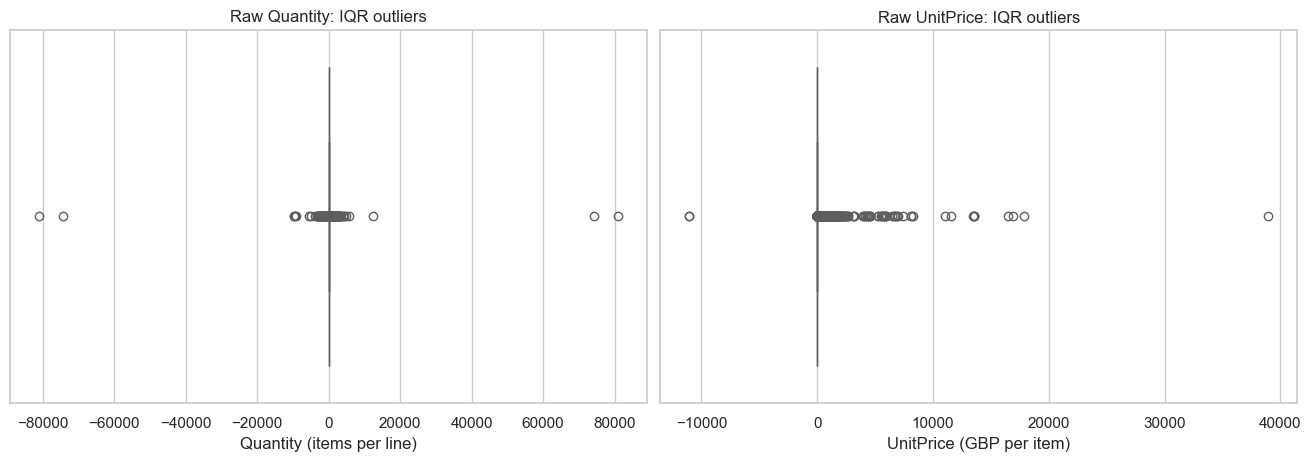

The IQR rule flags **58,619** quantity rows and **39,627** price rows. The long tails compress the boxes. More than one row in ten is flagged for quantity, which is too many to delete blindly, so the most extreme rows are inspected next.

In [4]:
def iqr_profile(series):
    values = pd.to_numeric(series, errors="coerce").dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((values < lower) | (values > upper)).sum())
    return {"Q1": q1, "Q3": q3, "IQR": iqr, "Lower bound": lower,
            "Upper bound": upper, "Outlier rows": count,
            "Outlier %": 100 * count / len(values)}

outlier_table = pd.DataFrame({name: iqr_profile(raw_df[name])
                              for name in ["Quantity", "UnitPrice"]}).T
display(outlier_table.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, field in zip(axes, ["Quantity", "UnitPrice"]):
    sns.boxplot(x=raw_df[field], ax=ax, color="#6ca5ce", showfliers=True)
    ax.set_title(f"Raw {field}: IQR outliers")
    ax.set_xlabel(field + (" (items per line)" if field == "Quantity" else " (GBP per item)"))
plt.show()
display(Markdown(
    f"The IQR rule flags **{int(outlier_table.loc['Quantity', 'Outlier rows']):,}** "
    f"quantity rows and **{int(outlier_table.loc['UnitPrice', 'Outlier rows']):,}** "
    "price rows. The long tails compress the boxes. More than one row in ten is flagged for quantity, "
    "which is too many to delete blindly, so the most extreme rows are inspected next."
))


### 5.1 Inspecting the most extreme rows

In [5]:
extreme_cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "InvoiceDate"]  # CustomerID not displayed (PII)
print("Largest quantities:")
display(raw_df.nlargest(5, "Quantity")[extreme_cols])
print("Smallest (most negative) quantities:")
display(raw_df.nsmallest(5, "Quantity")[extreme_cols])
print("Highest unit prices:")
display(raw_df.nlargest(10, "UnitPrice")[extreme_cols])

Largest quantities:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,2011-11-25 15:57:00
74614,542504,37413,NaN,5568,0.00,2011-01-28 12:03:00
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,2011-10-27 12:26:00


Smallest (most negative) quantities:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,2011-12-09 09:27:00
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,2011-01-18 10:17:00
225529,556690,23005,printing smudges/thrown away,-9600,0.00,2011-06-14 10:37:00
225530,556691,23005,printing smudges/thrown away,-9600,0.00,2011-06-14 10:37:00
4287,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,0.03,2010-12-02 14:23:00


Highest unit prices:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate
222681,C556445,M,Manual,-1,38970.00,2011-06-10 15:31:00
524602,C580605,AMAZONFEE,AMAZON FEE,-1,17836.46,2011-12-05 11:36:00
43702,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02,2011-01-05 09:55:00
43703,C540118,AMAZONFEE,AMAZON FEE,-1,16453.71,2011-01-05 09:57:00
15016,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33,2010-12-07 15:04:00
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,2010-12-07 15:08:00
16356,C537651,AMAZONFEE,AMAZON FEE,-1,13541.33,2010-12-07 15:49:00
16232,C537644,AMAZONFEE,AMAZON FEE,-1,13474.79,2010-12-07 15:34:00
524601,C580604,AMAZONFEE,AMAZON FEE,-1,11586.50,2011-12-05 11:35:00
299982,A563185,B,Adjust bad debt,1,11062.06,2011-08-12 14:50:00


**What the extreme rows show:**

- The two largest quantities (**80,995** and **74,215**) each have an exact negative twin (`C581484` and `C541433`): the same product and quantity, cancelled 12 and 16 minutes later. The customer also matches; this is checked in 5.2 without displaying IDs. These are not real wholesale sales. If the cancellations are dropped and the originals are kept, the sales view counts goods that were never sold.
- The highest "unit prices" are not product prices at all. All ten highest belong to `M` (*Manual*), `AMAZONFEE` (*Amazon fee*) or `B` (*Adjust bad debt*, on an invoice starting with `A`), and most of them sit on cancelled invoices. Their "price" is a fee or an accounting adjustment.

So size alone does not tell us whether a row is valid. Next, the rows that share these two patterns are identified across the whole file.

### 5.2 Classifying outliers

**Same-day reversals.** A positive line is flagged as reversed when a cancellation for the same customer and stock code, with exactly the opposite quantity, follows within **24 hours**. Matching is one-to-one: each cancellation removes at most one sale, taking the closest one in time. The 24-hour window separates orders that were cancelled almost immediately, and so never became completed sales, from later returns of goods that were actually sold. Later returns belong to net-revenue analysis, not to this filter. Lines without a `CustomerID` cannot be matched, so this flag is a conservative lower bound.

**Non-product codes.** Regular product codes are five digits plus an optional letter suffix. Every code outside that pattern is listed below, and each one was reviewed by hand.

In [6]:
audit_df["Cancelled_invoice"] = audit_df["InvoiceNo"].str.upper().str.startswith("C").fillna(False)
code_upper = audit_df["StockCode"].str.upper()

# --- Same-day reversals (one-to-one, closest cancellation first) ---
match_keys = ["CustomerID", "Quantity"]
sales_side = (audit_df.loc[~audit_df["Cancelled_invoice"] & audit_df["Quantity"].gt(0)
                           & audit_df["CustomerID_present"], match_keys + ["InvoiceDate"]]
              .assign(Code=code_upper).reset_index(names="sale_row"))
cancel_side = (audit_df.loc[audit_df["Cancelled_invoice"] & audit_df["CustomerID_present"],
                            match_keys + ["InvoiceDate"]]
               .assign(Code=code_upper, Quantity=lambda d: -d["Quantity"])
               .reset_index(names="cancel_row"))
pairs = sales_side.merge(cancel_side, on=match_keys + ["Code"], suffixes=("_sale", "_cancel"))
pairs["Gap"] = pairs["InvoiceDate_cancel"] - pairs["InvoiceDate_sale"]
pairs = pairs[pairs["Gap"].between(pd.Timedelta(0), pd.Timedelta("24h"))]
pairs = pairs.sort_values("Gap").drop_duplicates("cancel_row").drop_duplicates("sale_row")
audit_df["Reversed_by_cancellation"] = audit_df.index.isin(pairs["sale_row"])

# --- Non-standard stock codes, listed for review ---
nonstandard = ~code_upper.str.match(r"^\d{5}[A-Z]{0,2}$").fillna(False)
code_review = (audit_df[nonstandard].groupby(code_upper[nonstandard])
               .agg(Rows=("Quantity", "size"),
                    Example_description=("Description", lambda s: s.dropna().mode().iloc[0] if s.notna().any() else pd.NA),
                    Median_price=("UnitPrice", "median"))
               .sort_values("Rows", ascending=False))
display(code_review)

,Rows,Example_description,Median_price
StockCode,,,
POST,1256,POSTAGE,18.000
DOT,710,DOTCOM POSTAGE,184.940
M,572,Manual,7.950
C2,144,CARRIAGE,50.000
D,77,Discount,22.970
S,63,SAMPLES,19.500
BANK CHARGES,37,Bank Charges,82.730
AMAZONFEE,34,AMAZON FEE,5909.875
CRUK,16,CRUK Commission,471.770


**Review decision.** Postage (`POST`, `DOT`), carriage (`C2`), fees (`AMAZONFEE`, `BANK CHARGES`, `CRUK` commission), manual or accounting entries (`M`, `D` discount, `B` bad debt), `S` samples, gift vouchers (`GIFT_…`) and `PADS` (a near-zero placeholder price of £0.001) are **not merchandise**. They are flagged as non-product lines. The `DCGS…` codes have real product names (party bags, dog collars, a night light), so they stay as products. The ones with no description are already excluded by the missing-description rule.

In [7]:
NON_PRODUCT_CODES = {"POST", "DOT", "C2", "AMAZONFEE", "BANK CHARGES", "CRUK",
                     "M", "D", "B", "S", "PADS"}
audit_df["Non_product_line"] = (code_upper.isin(NON_PRODUCT_CODES)
                                | code_upper.str.startswith("GIFT_").fillna(False))

# Classify every IQR outlier by what it is, not by its size
fences = outlier_table[["Lower bound", "Upper bound"]]
iqr_outlier = pd.Series(False, index=audit_df.index)
for field in ["Quantity", "UnitPrice"]:
    iqr_outlier |= ~audit_df[field].between(fences.loc[field, "Lower bound"], fences.loc[field, "Upper bound"])
outlier_class = np.select(
    [audit_df["Cancelled_invoice"],
     audit_df["Quantity"].le(0) | audit_df["UnitPrice"].le(0),
     audit_df["Non_product_line"],
     audit_df["Reversed_by_cancellation"]],
    ["Cancellation line (excluded, Section 6)",
     "Non-positive quantity/price (excluded, Section 6)",
     "Non-product / accounting line (excluded)",
     "Reversed within 24 h (excluded)"],
    default="Regular product line (kept, not capped)")
line_value = audit_df["Quantity"] * audit_df["UnitPrice"]
outlier_summary = (pd.DataFrame({"Class": outlier_class, "Value": line_value})[iqr_outlier]
                   .groupby("Class").agg(Rows=("Value", "size"), Line_value_GBP=("Value", "sum")))
display(outlier_summary.round(0))

reversed_rows = audit_df["Reversed_by_cancellation"]
nonprod_rows = audit_df["Non_product_line"] & ~audit_df["Cancelled_invoice"] & audit_df["UnitPrice"].gt(0)
kept_extremes = audit_df[iqr_outlier & (outlier_class == "Regular product line (kept, not capped)")]
display(Markdown(
    f"**{int(reversed_rows.sum()):,}** positive lines are reversed by a cancellation within 24 hours "
    f"(£{line_value[reversed_rows].sum():,.0f} of goods that were never sold), including the 80,995 and "
    f"74,215 unit orders. **{int(audit_df['Non_product_line'].sum()):,}** lines carry non-product codes, "
    f"and the positive-price ones amount to £{line_value[nonprod_rows].sum():,.0f}. "
    f"The remaining **{len(kept_extremes):,}** IQR outliers are regular product lines. Their maximum "
    f"quantity is {int(kept_extremes['Quantity'].max()):,} and their maximum unit price is "
    f"£{kept_extremes['UnitPrice'].max():,.2f}, both plausible for a wholesaler, so they are **kept "
    "uncapped**. Capping would change real quantities and understate revenue."
))

,Rows,Line_value_GBP
Class,,
"Cancellation line (excluded, Section 6)",2686,-842425.0
"Non-positive quantity/price (excluded, Section 6)",1177,-22124.0
Non-product / accounting line (excluded),2109,394381.0
"Regular product line (kept, not capped)",91546,5242973.0
Reversed within 24 h (excluded),283,325060.0


**670** positive lines are reversed by a cancellation within 24 hours (£339,293 of goods that were never sold), including the 80,995 and 74,215 unit orders. **2,950** lines carry non-product codes, and the positive-price ones amount to £395,251. The remaining **91,546** IQR outliers are regular product lines. Their maximum quantity is 4,800 and their maximum unit price is £649.50, both plausible for a wholesaler, so they are **kept uncapped**. Capping would change real quantities and understate revenue.

**Outlier handling summary**

| Outlier type | Evidence | Action | Reason |
|---|---|---|---|
| Positive line reversed within 24 h | Same customer and product, opposite quantity, cancellation follows within a day | Excluded from the sales view; kept in `audit_df` | The order never became a completed sale; keeping it would inflate quantity and revenue |
| Non-product / accounting line | Non-standard stock code reviewed in 5.2 | Excluded from the sales view; kept in `audit_df` | Not merchandise; its "unit price" is a fee or adjustment amount |
| Negative quantity / cancellation | `C` invoice prefix or quantity ≤ 0 | Excluded from the completed-sales view (Section 6) | A different transaction event, not a sale |
| Other positive extremes | Regular product codes, wholesale-sized orders | **Kept, not capped** | Plausible bulk purchases; capping would distort real values |

## 6. Other quality issues and sales-view rules

- **Wrong data types:** `CustomerID` was read as `float64` because of blanks. It was converted to a string identifier in Section 4 (`17850.0` → `"17850"`). `InvoiceNo` mixes integers and strings such as `C536379`, so it is stored as a string. Dates are parsed to `datetime`.
- **Inconsistent formats (StockCode case):** some codes appear in both upper and lower case, e.g. `15056BL` and `15056bl`. They are converted to upper case only after checking that both variants carry the same product description.
- **Inconsistent formats (descriptions):** many stock codes have several descriptions, either wording variants or internal notes typed into the description field. The original text is kept, and `Description_canonical` holds the most frequent description per code.
- **Inconsistent formats (country labels):** most countries are full names, but three are abbreviations: `EIRE`, `RSA` and `USA`. These are mapped to `Ireland`, `South Africa` and `United States`. `European Community` is not a country and has no verified equivalent, so it is kept as supplied and noted as ambiguous.
- **Invalid values:** cancellations (`C` prefix), adjustment invoices (`A` prefix), non-positive quantities or prices, and lines with a missing description or core field are excluded from the sales-ready view. Zero price could be a promotion, but it cannot support standard revenue calculations without context. Internal notes such as `damaged` or `?` sit on these non-positive lines, so the same rules already remove them.
- **Exact duplicates:** rows identical in every original column are flagged but **not deleted**. The source has no line-item key, so an identical row could be the same product scanned twice on one invoice. Their effect on the sales view is measured below so the decision can be checked.

In [8]:
# 6.1 Data types: raw inference vs. audit copy
display(pd.DataFrame({"Raw dtype": raw_df.dtypes.astype(str),
                      "Audit dtype": audit_df[raw_df.columns].dtypes.astype(str)}))

# 6.2 StockCode letter case: confirm variants describe the same product before merging them
upper_code = audit_df["StockCode"].str.upper()
variants = audit_df.groupby(upper_code)["StockCode"].nunique()
case_keys = variants[variants > 1].index
in_case_group = upper_code.isin(case_keys) & audit_df["Description"].notna()
case_desc = (audit_df[in_case_group]
             .groupby([upper_code[in_case_group].rename("Upper code"), "StockCode"])["Description"]
             .agg(lambda s: s.mode().iloc[0]))
same_product = case_desc.groupby(level=0).nunique().eq(1)
audit_df["StockCode_case_fixed"] = audit_df["StockCode"].ne(upper_code).fillna(False)
audit_df["StockCode"] = upper_code
display(Markdown(
    f"**{int(audit_df['StockCode_case_fixed'].sum()):,}** rows used a lower-case code. "
    f"**{int(same_product.sum())}** of **{len(same_product)}** case-variant groups share the same "
    "product description, so upper-casing merges duplicate spellings rather than different products. "
    "The groups whose variants differ are shown below:"
))
display(case_desc.loc[same_product[~same_product].index].to_frame())

# 6.3 Several descriptions per StockCode -> canonical (most frequent) description
desc_counts = (audit_df.dropna(subset=["Description"])
               .groupby(["StockCode", "Description"]).size().rename("Rows").reset_index()
               .sort_values(["StockCode", "Rows", "Description"], ascending=[True, False, True]))
canonical = desc_counts.drop_duplicates("StockCode").set_index("StockCode")["Description"]
audit_df["Description_canonical"] = audit_df["StockCode"].map(canonical)
n_desc = desc_counts.groupby("StockCode").size()
print(f"Stock codes with more than one description: {int((n_desc > 1).sum()):,} of {len(n_desc):,}")
display(desc_counts[desc_counts["StockCode"].isin(n_desc.nlargest(3).index)])

# 6.4 Country labels: abbreviations -> full names used elsewhere in the column
COUNTRY_MAP = {"EIRE": "Ireland", "RSA": "South Africa", "USA": "United States"}
audit_df["Country"] = audit_df["Country"].replace(COUNTRY_MAP)
print("Country labels after mapping:", audit_df["Country"].nunique(), "(Unspecified recoded to missing)")

# 6.5 Internal notes in Description on non-cancelled negative lines
notes = audit_df.loc[~audit_df["Cancelled_invoice"] & audit_df["Quantity"].lt(0), "Description"]
display(notes.value_counts(dropna=False).head(10).rename("Rows").to_frame())

,Raw dtype,Audit dtype
InvoiceNo,object,string
StockCode,object,string
Description,object,string
Quantity,int64,int64
InvoiceDate,datetime64[ns],datetime64[ns]
UnitPrice,float64,float64
CustomerID,float64,string
Country,object,string


**1,977** rows used a lower-case code. **110** of **112** case-variant groups share the same product description, so upper-casing merges duplicate spellings rather than different products. The groups whose variants differ are shown below:

Description
Upper code StockCode                                     
82001S     82001S               VINYL RECORD FRAME SILVER
           82001s               SILVER RECORD COVER FRAME
85184C     85184C       S/4 VALENTINE DECOUPAGE HEART BOX
           85184c     SET 4 VALENTINE DECOUPAGE HEART BOX

Stock codes with more than one description: 642 of 3,848


,StockCode,Description,Rows
192,20713,JUMBO BAG OWLS,673
191,20713,Found,1
193,20713,Marked as 23343,1
194,20713,found,1
195,20713,wrongly coded 23343,1
196,20713,wrongly coded-23343,1
197,20713,wrongly marked 23343,1
198,20713,wrongly marked. 23343 in box,1
1009,21830,ASSORTED CREEPY CRAWLIES,105
1008,21830,?,1


Country labels after mapping: 37 (Unspecified recoded to missing)


,Rows
Description,
<NA>,862
check,120
damages,45
damaged,42
?,41
sold as set on dotcom,20
Damaged,14
thrown away,9
"Unsaleable, destroyed.",9


In [9]:
audit_df["Exact_duplicate"] = raw_df.duplicated(keep="first")
audit_df["Adjustment_invoice"] = audit_df["InvoiceNo"].str.upper().str.startswith("A").fillna(False)
audit_df["Nonpositive_quantity"] = audit_df["Quantity"].isna() | audit_df["Quantity"].le(0)
audit_df["Nonpositive_price"] = audit_df["UnitPrice"].isna() | audit_df["UnitPrice"].le(0)
audit_df["Invalid_sales_line"] = (
    audit_df["Description_missing"] | audit_df["InvoiceDate_invalid"] |
    audit_df["InvoiceNo_missing"] | audit_df["StockCode_missing"] |
    audit_df["Country_missing"] | audit_df["Nonpositive_quantity"] |
    audit_df["Nonpositive_price"]
)
audit_df["Sales_eligible"] = ~(
    audit_df["Cancelled_invoice"] | audit_df["Adjustment_invoice"] | audit_df["Invalid_sales_line"] |
    audit_df["Non_product_line"] | audit_df["Reversed_by_cancellation"]
)

issue_counts = pd.Series({
    "Exact duplicate rows": int(audit_df["Exact_duplicate"].sum()),
    "Missing or blank descriptions": int(audit_df["Description_missing"].sum()),
    "Unspecified country (recoded to missing)": int(audit_df["Country_unspecified"].sum()),
    "Cancelled invoice rows": int(audit_df["Cancelled_invoice"].sum()),
    "Adjustment invoice rows (A prefix)": int(audit_df["Adjustment_invoice"].sum()),
    "Negative quantity rows": int(audit_df["Quantity"].lt(0).sum()),
    "Zero quantity rows": int(audit_df["Quantity"].eq(0).sum()),
    "Zero price rows": int(audit_df["UnitPrice"].eq(0).sum()),
    "Negative price rows": int(audit_df["UnitPrice"].lt(0).sum()),
    "Invalid date rows": int(audit_df["InvoiceDate_invalid"].sum()),
    "Non-cancelled invalid sales lines": int((~audit_df["Cancelled_invoice"] & audit_df["Invalid_sales_line"]).sum()),
    "Non-product / accounting lines": int(audit_df["Non_product_line"].sum()),
    "Lines reversed within 24 h": int(audit_df["Reversed_by_cancellation"].sum()),
    "Lower-case StockCode rows fixed": int(audit_df["StockCode_case_fixed"].sum()),
    "StockCodes with several descriptions": int((n_desc > 1).sum()),
}, name="Rows")
display(issue_counts.to_frame())

# Each excluded row is attributed to the first rule that applies, so the counts add up
exclusion_reason = pd.Series(np.select(
    [audit_df["Cancelled_invoice"], audit_df["Adjustment_invoice"],
     audit_df["Description_missing"] | audit_df["InvoiceDate_invalid"] | audit_df["InvoiceNo_missing"]
     | audit_df["StockCode_missing"] | audit_df["Country_missing"],
     audit_df["Nonpositive_quantity"] | audit_df["Nonpositive_price"],
     audit_df["Non_product_line"], audit_df["Reversed_by_cancellation"]],
    ["1. Cancelled invoice", "2. Adjustment invoice", "3. Missing description/core field",
     "4. Non-positive quantity/price", "5. Non-product / accounting line", "6. Reversed within 24 h"],
    default="Kept in sales view"), index=audit_df.index)
display(exclusion_reason.value_counts().sort_index().rename("Rows").to_frame())

sales_df = audit_df.loc[audit_df["Sales_eligible"],
    ["InvoiceNo", "StockCode", "Description", "Description_canonical", "Quantity", "InvoiceDate",
     "UnitPrice", "Country", "CustomerID_present"]].copy()
assert len(raw_df) == len(audit_df), "The audit copy must retain every raw row."
assert len(sales_df) + int((~audit_df["Sales_eligible"]).sum()) == len(raw_df)

sales_value = sales_df["Quantity"] * sales_df["UnitPrice"]
dup_in_sales = audit_df.loc[audit_df["Sales_eligible"], "Exact_duplicate"]
display(Markdown(
    f"**{len(sales_df):,}** of **{len(raw_df):,}** lines are eligible for the completed-sales view. "
    "The sales view omits raw `CustomerID`. "
    f"Exact duplicates remaining in the view: **{int(dup_in_sales.sum()):,}** lines worth "
    f"£{sales_value[dup_in_sales].sum():,.0f}, which is **{sales_value[dup_in_sales].sum() / sales_value.sum():.2%}** "
    "of sales-view value. In the worst case, where every one of them is an accidental re-entry, "
    "totals are overstated by less than a quarter of a percent. That is small enough to keep them "
    "flagged rather than delete lines that may be genuine."
))

,Rows
Exact duplicate rows,5268
Missing or blank descriptions,1454
Unspecified country (recoded to missing),446
Cancelled invoice rows,9288
Adjustment invoice rows (A prefix),3
Negative quantity rows,10624
Zero quantity rows,0
Zero price rows,2515
Negative price rows,2
Invalid date rows,0


,Rows
1. Cancelled invoice,9288
2. Adjustment invoice,3
3. Missing description/core field,1454
4. Non-positive quantity/price,1061
5. Non-product / accounting line,2345
6. Reversed within 24 h,641
Kept in sales view,527117


**527,117** of **541,909** lines are eligible for the completed-sales view. The sales view omits raw `CustomerID`. Exact duplicates remaining in the view: **5,210** lines worth £24,140, which is **0.24%** of sales-view value. In the worst case, where every one of them is an accidental re-entry, totals are overstated by less than a quarter of a percent. That is small enough to keep them flagged rather than delete lines that may be genuine.

## 7. Diagnostic visualizations

The outlier boxplots in Section 5 are the first labeled diagnostic figure. The next figures show missingness, country coverage, and the distribution of the sales view after outlier handling. These are quality and representativeness checks, not revenue or performance dashboards.

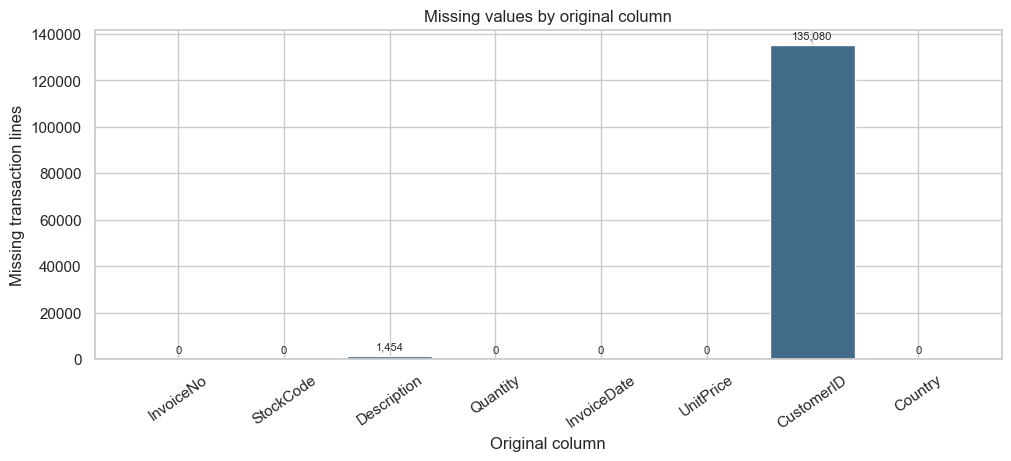

Missingness is concentrated in customer IDs and descriptions. The sales view has **446** missing values across its retained columns, all from `Country` lines whose `Unspecified` label was recoded to missing; customer-ID availability remains a separate flag.

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
bars = ax.bar(raw_missing.index, raw_missing.values, color="#426b89")
ax.bar_label(bars, labels=[f"{n:,}" for n in raw_missing], padding=3, fontsize=8)
ax.set_title("Missing values by original column")
ax.set_xlabel("Original column")
ax.set_ylabel("Missing transaction lines")
ax.tick_params(axis="x", rotation=35)
plt.show()
display(Markdown(
    "Missingness is concentrated in customer IDs and descriptions. "
    f"The sales view has **{int(sales_df.isna().sum().sum()):,}** missing values "
    "across its retained columns, all from `Country` lines whose `Unspecified` label was recoded "
    "to missing; customer-ID availability remains a separate flag."
))


,Rows,Row share %
Country,,
United Kingdom,495478,91.43
Germany,9495,1.75
France,8557,1.58
EIRE,8196,1.51
Spain,2533,0.47
Netherlands,2371,0.44
Belgium,2069,0.38
Switzerland,2002,0.37
Portugal,1519,0.28


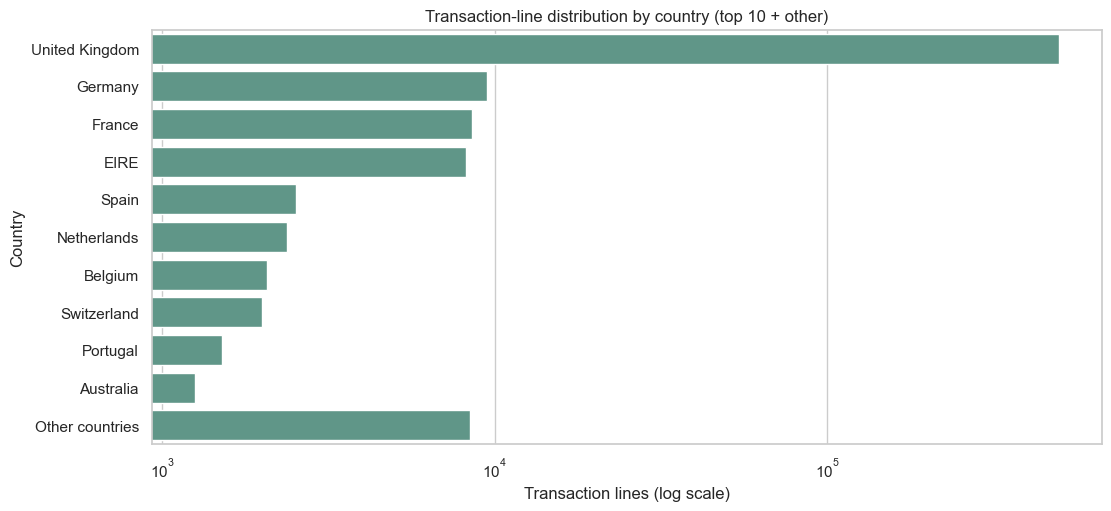

The largest country accounts for **91.43%** of original rows (United Kingdom). This concentration limits generalization to other countries; it does not by itself prove discrimination. The logarithmic axis keeps smaller country groups visible.

In [11]:
country_counts = raw_df["Country"].fillna("<missing>").value_counts()
country_shares = country_counts.div(len(raw_df)).mul(100)
display(pd.DataFrame({"Rows": country_counts, "Row share %": country_shares.round(2)}))
top_n = 10
plot_counts = country_counts.head(top_n).copy()
if len(country_counts) > top_n:
    plot_counts.loc["Other countries"] = country_counts.iloc[top_n:].sum()
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
sns.barplot(x=plot_counts.values, y=plot_counts.index, ax=ax, color="#579f8c")
ax.set_xscale("log")
ax.set_title("Transaction-line distribution by country (top 10 + other)")
ax.set_xlabel("Transaction lines (log scale)")
ax.set_ylabel("Country")
plt.show()
display(Markdown(
    f"The largest country accounts for **{country_shares.iloc[0]:.2f}%** "
    f"of original rows ({country_counts.index[0]}). This concentration limits "
    "generalization to other countries; it does not by itself prove discrimination. "
    "The logarithmic axis keeps smaller country groups visible."
))


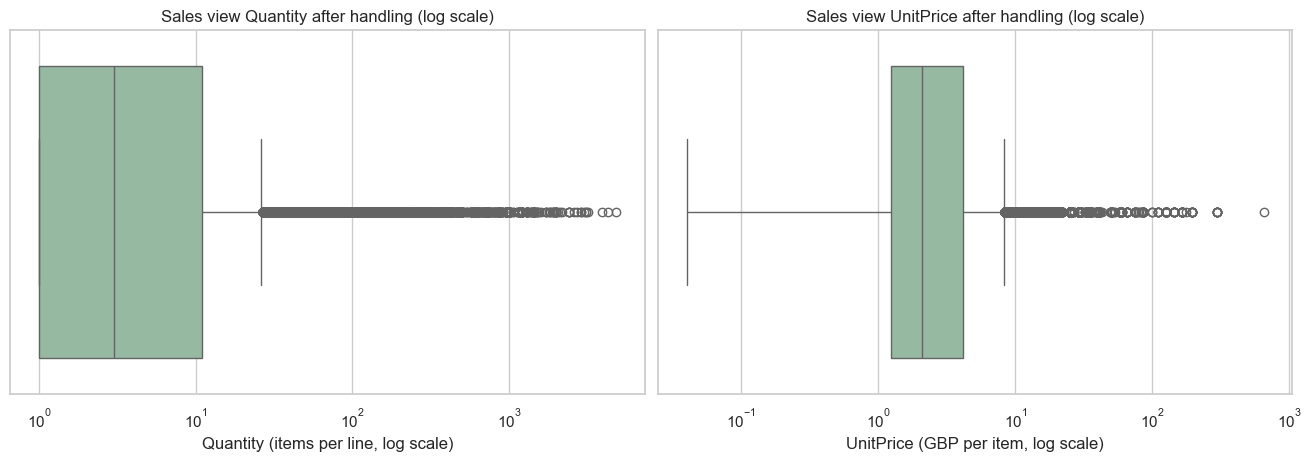

After excluding reversals, non-product lines and invalid rows, the maximum quantity is **4,800** (was 80,995) and the maximum unit price is **£649.50** (was £38,970.00). The remaining tail is made of genuine product lines, kept on purpose.

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, field, unit in zip(axes, ["Quantity", "UnitPrice"], ["items per line", "GBP per item"]):
    sns.boxplot(x=sales_df[field], ax=ax, color="#8fbf9f", showfliers=True)
    ax.set_xscale("log")
    ax.set_title(f"Sales view {field} after handling (log scale)")
    ax.set_xlabel(f"{field} ({unit}, log scale)")
plt.show()
display(Markdown(
    f"After excluding reversals, non-product lines and invalid rows, the maximum quantity is "
    f"**{int(sales_df['Quantity'].max()):,}** (was {int(raw_df['Quantity'].max()):,}) and the maximum unit price is "
    f"**£{sales_df['UnitPrice'].max():,.2f}** (was £{raw_df['UnitPrice'].max():,.2f}). "
    "The remaining tail is made of genuine product lines, kept on purpose."
))

## 8. PII and bias risks

`CustomerID` is a pseudonymous-looking identifier, not necessarily direct PII by itself. If linked with account or purchase-history data, it may enable re-identification. Raw identifiers should be access restricted; if customer-level work is approved, a controlled pseudonymization map can replace them and be stored separately. This notebook exposes only aggregate missingness and a boolean availability flag in `sales_df`, not customer identifiers in the cleaned output.

Country is both a useful coverage variable and a possible source of geographic or sampling bias. The country shares above measure line counts, not unique customers, invoices, or population rates. The UK retailer's clientele, wholesale mix, time window, and missing customer IDs constrain comparisons; a country imbalance alone is not evidence of unfair treatment. Country-stratified checks and additional data would be needed before extending conclusions beyond this retailer.


## 9. Data-quality summary and before/after comparison

Findings are calculated from the workbook. Rows can have several flags, so issue counts should not be summed to reconstruct the number excluded. The audit copy is retained; `sales_df` is a purpose-specific selection.


In [13]:
summary = pd.DataFrame([
    ["CustomerID missing", "isna()", f"{raw_missing['CustomerID']:,} rows ({raw_missing_pct['CustomerID']:.2f}%)", "Flag availability; omit ID from sales view", "Sale can exist without customer identity; avoid fabrication and exposure"],
    ["Description missing/blank", "isna() or empty after trim", f"{issue_counts['Missing or blank descriptions']:,} rows", "Exclude from sales view; retain in audit", "Mostly zero-price adjustments; product meaning cannot be checked"],
    ["Country 'Unspecified'", "Placeholder label check", f"{issue_counts['Unspecified country (recoded to missing)']:,} rows", "Recode to missing and flag; keep the sale", "Disguised missing value; sale valid but country unknown"],
    ["Quantity IQR outliers", "1.5 × IQR fences + inspection", f"{int(outlier_table.loc['Quantity', 'Outlier rows']):,} rows", "Classify; exclude reversals and non-products; keep the rest uncapped", "Largest quantities were cancelled within minutes; other extremes are plausible wholesale"],
    ["UnitPrice IQR outliers", "1.5 × IQR fences + inspection", f"{int(outlier_table.loc['UnitPrice', 'Outlier rows']):,} rows", "Exclude non-product lines; keep product extremes", "Highest 'prices' were fees, postage and adjustments"],
    ["Same-day reversals", "Opposite-quantity cancellation within 24 h", f"{issue_counts['Lines reversed within 24 h']:,} rows", "Exclude from sales view", "Order never became a completed sale"],
    ["Non-product codes", "Non-standard StockCode review", f"{issue_counts['Non-product / accounting lines']:,} rows", "Exclude from sales view", "Postage, fees, vouchers and accounting entries are not merchandise"],
    ["Exact duplicates", "duplicated() across source columns", f"{raw_duplicate_count:,} rows", "Flag; do not delete; impact measured", "No line-item key to prove redundancy; impact < 0.25% of value"],
    ["Cancelled / adjustment invoices", "InvoiceNo prefix C / A", f"{issue_counts['Cancelled invoice rows']:,} C rows; {issue_counts['Adjustment invoice rows (A prefix)']:,} A rows", "Exclude from completed-sales view", "Different transaction events, not sales"],
    ["Non-positive quantity/price", "Numeric comparison", f"{issue_counts['Negative quantity rows']:,} negative quantities; {int(issue_counts['Zero price rows'] + issue_counts['Negative price rows']):,} non-positive prices", "Exclude from completed-sales view", "Not valid for ordinary positive sales totals without context"],
    ["Wrong data types", "dtype inspection", "CustomerID float64; InvoiceNo mixed int/str", "Convert IDs to strings; parse dates", "Identifiers are labels, not measurements"],
    ["StockCode case variants", "upper() + description check", f"{issue_counts['Lower-case StockCode rows fixed']:,} rows", "Upper-case after verifying same product", "Same product spelled two ways"],
    ["Several descriptions per code", "nunique() per StockCode", f"{issue_counts['StockCodes with several descriptions']:,} codes", "Add Description_canonical; keep original", "Wording variants and typed notes"],
    ["Country abbreviations", "value_counts() review", "EIRE, RSA, USA", "Map to full country names", "Consistent naming for grouping"],
    ["Country concentration", "value_counts(normalize=True)", f"{country_shares.iloc[0]:.2f}% of rows in {country_counts.index[0]}", "Report limitation", "Coverage is not geographically representative"],
], columns=["Issue", "Detection Method", "Finding", "Action Taken", "Justification"])
with pd.option_context("display.max_colwidth", None):
    display(summary)

raw_value = raw_df["Quantity"] * raw_df["UnitPrice"]
comparison = pd.DataFrame({
    "Measure": ["Rows", "Missing descriptions", "Missing or unspecified country", "CustomerID missing",
                "Exact duplicate rows", "Non-cancelled invalid sales lines", "Non-product / accounting lines",
                "Lines reversed within 24 h", "Maximum quantity", "Maximum unit price (GBP)"],
    "Original workbook": [len(raw_df), int(raw_missing["Description"]),
                          int(raw_missing["Country"]) + issue_counts["Unspecified country (recoded to missing)"],
                          int(raw_missing["CustomerID"]), raw_duplicate_count,
                          int(issue_counts["Non-cancelled invalid sales lines"]),
                          issue_counts["Non-product / accounting lines"], issue_counts["Lines reversed within 24 h"],
                          int(raw_df["Quantity"].max()), round(float(raw_df["UnitPrice"].max()), 2)],
    "Sales-ready view": [len(sales_df), int(sales_df["Description"].isna().sum()),
                         f"{int(sales_df['Country'].isna().sum()):,} (kept, flagged)",
                         "ID omitted; availability flag retained", int(dup_in_sales.sum()), 0, 0, 0,
                         int(sales_df["Quantity"].max()), round(float(sales_df["UnitPrice"].max()), 2)],
}, dtype=object)
display(comparison)
print("Sales-view missing counts:")
display(sales_df.isna().sum().rename("Missing rows").to_frame())

,Issue,Detection Method,Finding,Action Taken,Justification
0,CustomerID missing,isna(),"135,080 rows (24.93%)",Flag availability; omit ID from sales view,Sale can exist without customer identity; avoid fabrication and exposure
1,Description missing/blank,isna() or empty after trim,"1,454 rows",Exclude from sales view; retain in audit,Mostly zero-price adjustments; product meaning cannot be checked
2,Country 'Unspecified',Placeholder label check,446 rows,Recode to missing and flag; keep the sale,Disguised missing value; sale valid but country unknown
3,Quantity IQR outliers,1.5 × IQR fences + inspection,"58,619 rows",Classify; exclude reversals and non-products; keep the rest uncapped,Largest quantities were cancelled within minutes; other extremes are plausible wholesale
4,UnitPrice IQR outliers,1.5 × IQR fences + inspection,"39,627 rows",Exclude non-product lines; keep product extremes,"Highest 'prices' were fees, postage and adjustments"
5,Same-day reversals,Opposite-quantity cancellation within 24 h,670 rows,Exclude from sales view,Order never became a completed sale
6,Non-product codes,Non-standard StockCode review,"2,950 rows",Exclude from sales view,"Postage, fees, vouchers and accounting entries are not merchandise"
7,Exact duplicates,duplicated() across source columns,"5,268 rows",Flag; do not delete; impact measured,No line-item key to prove redundancy; impact < 0.25% of value
8,Cancelled / adjustment invoices,InvoiceNo prefix C / A,"9,288 C rows; 3 A rows",Exclude from completed-sales view,"Different transaction events, not sales"
9,Non-positive quantity/price,Numeric comparison,"10,624 negative quantities; 2,517 non-positive prices",Exclude from completed-sales view,Not valid for ordinary positive sales totals without context


,Measure,Original workbook,Sales-ready view
0,Rows,541909,527117
1,Missing descriptions,1454,0
2,Missing or unspecified country,446,"446 (kept, flagged)"
3,CustomerID missing,135080,ID omitted; availability flag retained
4,Exact duplicate rows,5268,5210
5,Non-cancelled invalid sales lines,2517,0
6,Non-product / accounting lines,2950,0
7,Lines reversed within 24 h,670,0
8,Maximum quantity,80995,4800
9,Maximum unit price (GBP),38970.0,649.5


Sales-view missing counts:


,Missing rows
InvoiceNo,0
StockCode,0
Description,0
Description_canonical,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,446
CustomerID_present,0


## 10. Conclusion

The final judgment below is generated from the measured rows. The sales-ready view is intended for **descriptive analysis of completed, positive-price product lines**, while the audit copy retains cancellations and suspect lines for further investigation. It should not be used as a complete record of returns, as proof that duplicate lines are errors, or as representative evidence for every country or customer.


In [14]:
excluded = len(raw_df) - len(sales_df)
display(Markdown(
    f"The original workbook contains **{len(raw_df):,}** transaction lines. "
    f"The sales-ready view contains **{len(sales_df):,}** lines after **{excluded:,}** "
    "lines were excluded by documented rules (see the exclusion table in Section 6). The main problems were "
    f"missing customer IDs ({raw_missing['CustomerID']:,}), missing or blank descriptions "
    f"({issue_counts['Missing or blank descriptions']:,}), a disguised missing country label "
    f"({issue_counts['Unspecified country (recoded to missing)']:,}), exact duplicate rows ({raw_duplicate_count:,}), "
    f"cancellations ({issue_counts['Cancelled invoice rows']:,}), orders reversed within 24 hours "
    f"({issue_counts['Lines reversed within 24 h']:,}, including the two largest quantities), non-product "
    f"and accounting lines ({issue_counts['Non-product / accounting lines']:,}, including every one of the highest "
    "'unit prices'), and non-positive quantities or prices. Identifier types, stock-code case, "
    "country abbreviations and description variants were made consistent. Missing customer IDs were "
    "flagged, not imputed. Outliers were inspected and classified rather than capped: regular product "
    "extremes were kept as plausible wholesale orders. "
    "**The selected view is fit for cautious descriptive sales analysis of completed, positive-price "
    "product lines for this retailer and period.** It is not fit for customer-level analysis without "
    "further identity controls, nor for full net-revenue/returns analysis without reconciling later returns "
    "and adjustments. Remaining limits: reversal matching is approximate and cannot cover lines without a "
    "customer ID; duplicate lines may still include a few re-entries (< 0.25% of value); "
    f"{int(sales_df['Country'].isna().sum()):,} sales lines have no known country; and "
    f"**{country_shares.iloc[0]:.2f}%** of rows come from {country_counts.index[0]}, which limits "
    "generalization to other countries."
))

The original workbook contains **541,909** transaction lines. The sales-ready view contains **527,117** lines after **14,792** lines were excluded by documented rules (see the exclusion table in Section 6). The main problems were missing customer IDs (135,080), missing or blank descriptions (1,454), a disguised missing country label (446), exact duplicate rows (5,268), cancellations (9,288), orders reversed within 24 hours (670, including the two largest quantities), non-product and accounting lines (2,950, including every one of the highest 'unit prices'), and non-positive quantities or prices. Identifier types, stock-code case, country abbreviations and description variants were made consistent. Missing customer IDs were flagged, not imputed. Outliers were inspected and classified rather than capped: regular product extremes were kept as plausible wholesale orders. **The selected view is fit for cautious descriptive sales analysis of completed, positive-price product lines for this retailer and period.** It is not fit for customer-level analysis without further identity controls, nor for full net-revenue/returns analysis without reconciling later returns and adjustments. Remaining limits: reversal matching is approximate and cannot cover lines without a customer ID; duplicate lines may still include a few re-entries (< 0.25% of value); 446 sales lines have no known country; and **91.43%** of rows come from United Kingdom, which limits generalization to other countries.